In [1]:
import pandas as pd

In [5]:
df = pd.read_csv('C:\\Users\\muniz\\Documents\\EcommerceProject\\dataset\\retail_data.csv')

In [ ]:
df['InvoiceNo'] = df['InvoiceNo'].astype(str) # ajuda a evitar erros, caso alguns numeros tenham sido lidos como inteiros


In [8]:
df_limpo = df[~df['InvoiceNo'].str.startswith('C')].copy() # remove linhas das faturas que começam com C, que sao devolucoes e ou cancelamentos

In [9]:
df_limpo = df_limpo[df_limpo['Quantity'] >0 ].copy() # remove linhas que tem quatidade negativa ou zero, que são devoluções ou cancelamentos

In [10]:
print("Tamanho apos limpeza de cancelamento:", df_limpo.shape) # confere o tamanho apos a limpeza 

Tamanho apos limpeza de cancelamento: (531285, 8)


In [11]:
df_limpo.to_csv('online_retail_cleaned.csv', index=False) # salva o arquivo limpo em csv

### Inciando a identificação de 'produtos estrela' abaixo

In [13]:
df = pd.read_csv('C:\\Users\\muniz\\Documents\\EcommerceProject\\dataset\\online_retail_cleaned.csv')

C:\Users\muniz\AppData\Local\Temp\ipykernel_63664\129027614.py:1: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('C:\\Users\\muniz\\Documents\\EcommerceProject\\dataset\\online_retail_cleaned.csv')


In [18]:
#adicionada para forçar a conversão para numerico, pois antes sem ela, o resultado ficava com muitos numeros em notação cientifica, o que dificultava a leitura
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce')


In [19]:
df['ReceitaTotal'] = df['Quantity'] * df['UnitPrice'] # cria coluna de receita total


In [20]:
produtos_estrela = df.groupby(['StockCode', 'Description'])['ReceitaTotal'].sum().reset_index() # agrupa pelo codigo do produto e descrição para somar a receita de cada produto 
# o codigo evita que produtos semelhantes se misturem 

In [21]:
produtos_estrela = produtos_estrela.sort_values(by='ReceitaTotal', ascending=False) # orneda o faturamento do maior para o menor

In [22]:
top_5 = produtos_estrela.head(5)
print("Top 5 produtos estra (por receita total):")
print(top_5.to_string(index=False))

Top 5 produtos estra (por receita total):
StockCode                 Description  ReceitaTotal
     POST                     POSTAGE       69187.0
      DOT              DOTCOM POSTAGE        9824.0
    22655 VINTAGE RED KITCHEN CABINET        8125.0
        M                      Manual        7456.0
       C2                    CARRIAGE        7051.0


In [23]:
produtos_estrela.to_csv('produtos_estrela.csv', index=False) # salva para csv o arquivo com resultado correto na tabela receitatotal
print("Tabela salva com sucesso em produtos_estrela.csv.")

Tabela salva com sucesso em produtos_estrela.csv.


### Visualização dos gráficos

In [26]:
import matplotlib.pyplot as plt

In [48]:
# verifica se tudo foi carregado corretamente e se os valores estao como numericos
df = pd.read_csv('C:\\Users\\muniz\\Documents\\EcommerceProject\\dataset\\online_retail_cleaned.csv', low_memory=False) # issp retira o aviso de erro de memoria, mas pode ser mais lento para ler o arquivo
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce')
df = df.dropna(subset=['Quantity', 'UnitPrice'])
df['ReceitaTotal'] = df['Quantity'] * df['UnitPrice']

# debug para mostrar que esta tudo ok
print(f"Linhas do DF após a limpeza: {len(df)}")

Linhas do DF após a limpeza: 3019


In [50]:
# agrupamento de top 5 paises por receita total
top_paises = df.groupby('Country')['ReceitaTotal'].sum().sort_values(ascending=False).head(5)
# aqui colocamos um truque, cortamos os nomes de produtos com mais de 30 char para o eixo Y não bugar
top_produtos.index = [nome[:30] + '...' if len(str(nome)) > 30 else nome for nome in top_produtos.index]

In [61]:
# agrupamento de top 5 produtos por receita total
top_produtos = df.groupby('Country')['ReceitaTotal'].sum().sort_values(ascending=False).head(5)


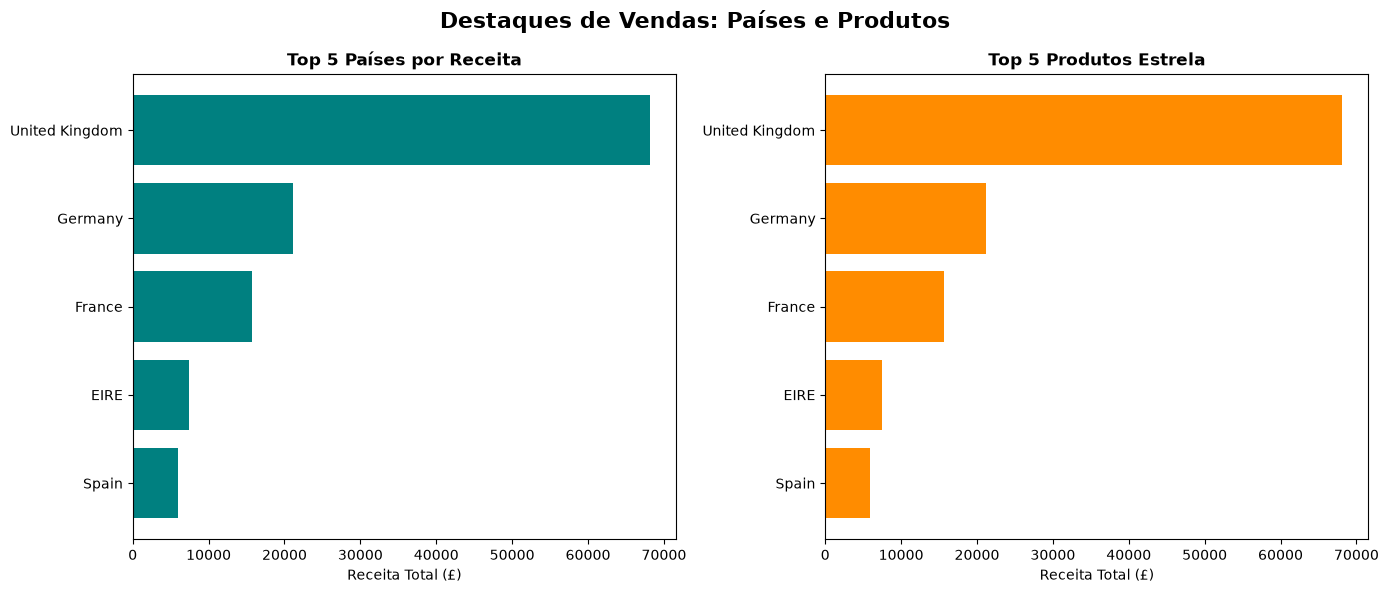

In [63]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Destaques de Vendas: Países e Produtos', fontsize=16, fontweight='bold')

# trocamos para ax.barh - mais estavel
ax1.barh(top_paises.index, top_paises.values, color='teal')
ax1.set_title('Top 5 Países por Receita', fontsize=12, fontweight='bold')
ax1.set_xlabel('Receita Total (£)')
ax1.invert_yaxis() # 1º lugar no topo

ax2.barh(top_produtos.index, top_produtos.values, color='darkorange')
ax2.set_title('Top 5 Produtos Estrela', fontsize=12, fontweight='bold')
ax2.set_xlabel('Receita Total (£)')
ax2.invert_yaxis() # 1º lugar no topo

# 6. Ajustar e exibir
plt.tight_layout()
plt.show()

### Análise de RFM (Recência, Freqência e Valor Monetário)

In [69]:
import numpy as np

df = pd.read_csv('C:\\Users\\muniz\\Documents\\EcommerceProject\\dataset\\online_retail_cleaned.csv', low_memory=False)
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce')
df = df.dropna(subset=['Quantity', 'UnitPrice'])
df['ReceitaTotal'] = df['Quantity'] * df['UnitPrice']

In [70]:
# convertemos a coluna de data para o formato correto do pandas
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


C:\Users\muniz\AppData\Local\Temp\ipykernel_63664\2573980525.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


In [71]:
# filtrar apenas clientes que tem ID para o RFM
df_clientes = df[df['CustomerID'].notna()].copy()

In [72]:
# defini a data de hoje como a data mais recente presente no dataset, para que o RFM seja calculado com base na data mais recente do dataset
data_referencia = df_clientes['InvoiceDate'].max()


In [74]:
# agrupamento por cliente para calcular RFM
rfm = df_clientes.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (data_referencia - x.max()).days, # Recência: dias desde a última compra
    'InvoiceNo': 'nunique',                                     # Frequência: número de compras únicas
    'ReceitaTotal': 'sum'                                       # Monetário: valor total gasto
}).rename(columns={
    'InvoiceDate': 'Recencia_Dias',
    'InvoiceNo': 'Frequencia',
    'ReceitaTotal': 'Monetario'
})


In [75]:
# cria uma segmentação simples com top 20% vs resto para cada metrica
rfm['Score_R'] = rfm['Recencia_Dias'].rank(pct=True)
rfm['Score_F'] = rfm['Frequencia'].rank(pct=True)
rfm['Score_M'] = rfm['Monetario'].rank(pct=True)

In [76]:
# classificar o cliente com base nos scores
# se estiver no top 20% em F e M, é 'campeao'
condicao_campeao = (rfm['Score_F'] >= 0.8) & (rfm['Score_M'] >= 0.8)
rfm['Segmento'] = np.where(condicao_campeao, 'Campeão', 'Cliente Padrão')


In [77]:
# visualização 
print("Resumo da Segmentação de Clientes:")
print(rfm['Segmento'].value_counts())

print("\n Exemplo dos Top 5 Campeões (Maiores Gastadores e Mais Frequentes):")
campeoes = rfm[rfm['Segmento'] == 'Campeão'].sort_values(by='Monetario', ascending=False).head(5)
print(campeoes[['Recencia_Dias', 'Frequencia', 'Monetario']].round(2))

Resumo da Segmentação de Clientes:
Segmento
Cliente Padrão    575
Campeão            74
Name: count, dtype: int64

 Exemplo dos Top 5 Campeões (Maiores Gastadores e Mais Frequentes):
            Recencia_Dias  Frequencia  Monetario
CustomerID                                      
17450.0                17           6    10496.0
14911.0                 4          87     4364.0
12471.0                 1          21     2400.0
14607.0                17           4     2120.0
12540.0                19          17     1820.0


### Sazonalidade

In [90]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('C:\\Users\\muniz\\Documents\\EcommerceProject\\dataset\\online_retail_cleaned.csv', low_memory=False)
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce')
df = df.dropna(subset=['Quantity', 'UnitPrice'])
df['ReceitaTotal'] = df['Quantity'] * df['UnitPrice']
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

C:\Users\muniz\AppData\Local\Temp\ipykernel_63664\2089891685.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


In [91]:
# extração do mes e ano para a analise de tendencia
df['Ano'] = df['InvoiceDate'].dt.year
df['Mes'] = df['InvoiceDate'].dt.month


In [92]:
# agrupar por ano e mes para somar a receita de cada periodo
vendas_mensais = df.groupby(['Ano', 'Mes'])['ReceitaTotal'].sum().reset_index()


In [93]:
# alterado juntamos ano, mes e dia 01 como texto e depois convertemos para data
vendas_mensais['Data'] = pd.to_datetime(
    vendas_mensais['Ano'].astype(str) + '-' + vendas_mensais['Mes'].astype(str) + '-01'
)

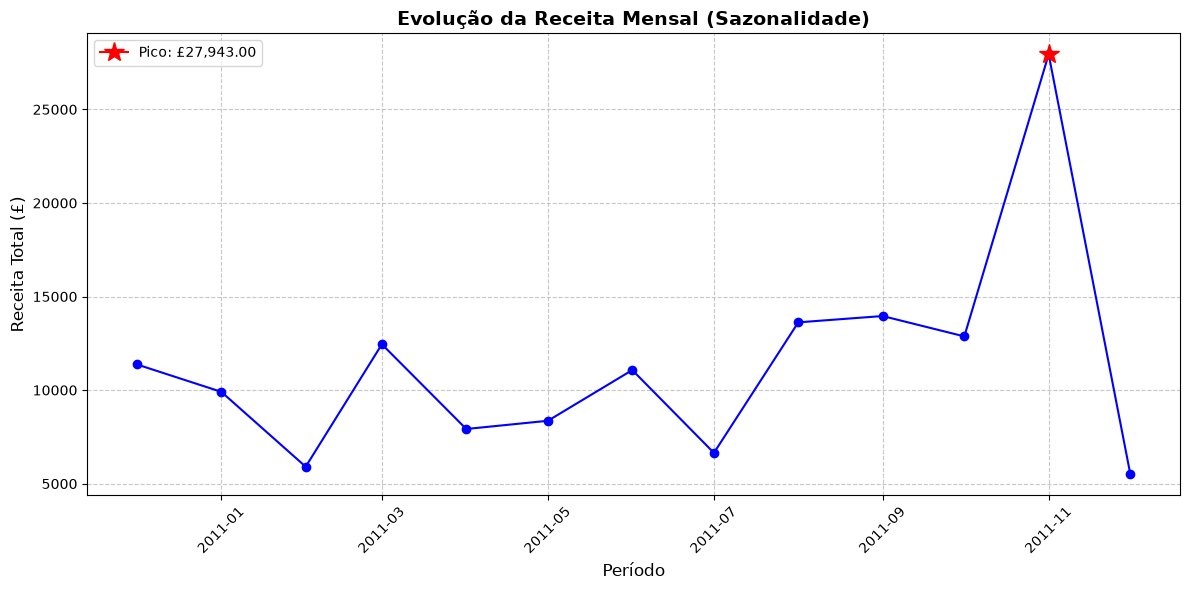

In [97]:
plt.figure(figsize=(12, 6))
plt.plot(vendas_mensais['Data'], vendas_mensais['ReceitaTotal'], marker='o', linestyle='-', color='b')

# Configurações visuais (deixando com cara de dashboard profissional)
plt.title('Evolução da Receita Mensal (Sazonalidade)', fontsize=14, fontweight='bold')
plt.xlabel('Período', fontsize=12)
plt.ylabel('Receita Total (£)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

# Destacar o ponto de pico (a maior venda)
pico = vendas_mensais.loc[vendas_mensais['ReceitaTotal'].idxmax()]
# a linha abaixo foi mudada para montar a data diretamente com valores da Series, para retirar o erro
pico_data = pd.to_datetime(f"{int(pico['Ano'])}-{int(pico['Mes'])}-01")
plt.plot(pico_data, pico['ReceitaTotal'], marker='*', color='red', markersize=15, label=f'Pico: £{pico["ReceitaTotal"]:,.2f}')
plt.legend()

plt.tight_layout()
plt.show()